# 03 – Modelagem: baseline, Regressão Linear e SVR

Itens 3 (seleção do método) e 5 (implementação) do roteiro.

**Protocolo**
- Só a safra **2023** é usada aqui. A safra 2025 não é carregada neste notebook.
- Validação cruzada **KFold com k = 5, embaralhada, `random_state = 42`**, igual para todos os modelos.
- Métricas: **RMSE** (penaliza erros grandes, na escala do IDEB), **MAE** (erro típico em pontos de IDEB) e **R²** (parcela da variação explicada).
- Todo pré-processamento que aprende com os dados (winsorização p1/p99, imputação pela mediana, padronização, one-hot) fica dentro do `Pipeline` e é ajustado só no treino de cada dobra.

**Por que estes modelos (lista da disciplina: Mean Shift, GMM, DBSCAN, Regressão Linear, Regressão Logística e SVM)**

| Modelo | Papel | Justificativa |
|---|---|---|
| Regressão Linear | Principal | O alvo é contínuo. Com as features padronizadas, cada coeficiente diz quanto o IDEB esperado muda quando o fator varia um desvio-padrão, mantidos os demais. É o que o gestor precisa saber, e é fácil de explicar. |
| SVR (SVM para regressão, kernel RBF) | Desafiante | Capta relações não lineares e interações (ex.: gasto com retorno decrescente). Em troca, não tem coeficientes, e a interpretação depende de permutation importance. |
| Regressão Logística | Complementar | Só responde se a pergunta virar classificação ("o município atinge IDEB 6,0?"). Incluímos uma análise curta no fim. |
| GMM, DBSCAN, Mean Shift | Descartados | São agrupamentos não supervisionados: encontram perfis de municípios, mas não estimam o IDEB, que é a pergunta do problema. |

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from statsmodels.stats.outliers_influence import variance_inflation_factor

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'notebooks'))
import estilo_graficos as eg
import modelagem as md
from estilo_graficos import br

FIGURAS = RAIZ / 'figuras'
PROCESSADOS = RAIZ / 'dados' / 'processados'
eg.aplicar_estilo()
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: br(x, 3))

config = json.loads((PROCESSADOS / 'features.json').read_text(encoding='utf-8'))
NUMERICAS, ALVO = config['numericas'], config['alvo']
GRUPOS = config['grupos']

base = pd.read_csv(PROCESSADOS / 'base_modelagem.csv')
treino = base[base['ano'] == config['ano_treino']].reset_index(drop=True)
del base  # 2025 fica fora deste notebook
# Entradas: só as features e as colunas categóricas. O alvo fica separado em y.
X = treino[NUMERICAS + ['sigla_uf', 'regiao']]
y = treino[ALVO]
assert ALVO not in X.columns
print(f'Treino: {br(len(treino))} municípios de {treino["sigla_uf"].nunique()} UFs, '
      f'{len(NUMERICAS)} features numéricas')

Treino: 5.241 municípios de 26 UFs, 24 features numéricas


In [2]:
CV = KFold(n_splits=5, shuffle=True, random_state=42)
PONTUACAO = {'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error', 'R²': 'r2'}
resultados = {}


def avaliar(nome, estimador):
    """Validação cruzada com as mesmas dobras para todos os modelos."""
    inicio = time.time()
    r = cross_validate(estimador, X, y, cv=CV, scoring=PONTUACAO, n_jobs=-1)
    dobras = pd.DataFrame({'RMSE': -r['test_RMSE'], 'MAE': -r['test_MAE'], 'R²': r['test_R²']})
    resultados[nome] = dobras
    resumo = dobras.agg(['mean', 'std'])
    print(f'{nome:<42} RMSE {br(resumo.loc["mean", "RMSE"], 3)} (±{br(resumo.loc["std", "RMSE"], 3)})  '
          f'MAE {br(resumo.loc["mean", "MAE"], 3)}  R² {br(resumo.loc["mean", "R²"], 3)}  '
          f'[{time.time() - inicio:.0f} s]')
    return dobras


def pipeline_linear(numericas, categoricas):
    return Pipeline([('prep', md.montar_preprocessador(numericas, categoricas)),
                     ('modelo', LinearRegression())])

## 1. Baseline: média do IDEB da UF

Qualquer modelo precisa superar a previsão mais simples que um analista faria sem modelo: "o município deve ter o IDEB médio do seu estado". A média é calculada só com os municípios da dobra de treino.

In [3]:
_ = avaliar('Baseline: média da UF', md.BaselineMediaUF())

Baseline: média da UF                      RMSE 0,686 (±0,015)  MAE 0,523  R² 0,475  [9 s]


## 2. Regressão Linear com região (especificação planejada)

In [4]:
_ = avaliar('Regressão Linear + região', pipeline_linear(NUMERICAS, ['regiao']))

Regressão Linear + região                  RMSE 0,733 (±0,014)  MAE 0,543  R² 0,402  [4 s]


**Desafio:** a Regressão Linear com as 24 features e a região **erra mais que o baseline** que só conhece a UF. A região é grossa demais: o Nordeste junta o Ceará, que fica bem acima da tendência, com estados que ficam abaixo (notebook 01, seção 5.2). O que diferencia os estados (políticas estaduais, regime de colaboração com os municípios, ICMS educacional) não aparece em nenhuma variável municipal.

**Ajuste:** trocar a região pela **UF em one-hot** (25 colunas, com uma UF de referência). Com isso, os coeficientes das demais features passam a comparar municípios **dentro do mesmo estado**, o que também é mais justo para o gestor.

In [5]:
_ = avaliar('Regressão Linear + UF', pipeline_linear(NUMERICAS, ['sigla_uf']))

Regressão Linear + UF                      RMSE 0,642 (±0,017)  MAE 0,484  R² 0,541  [0 s]


### 2.1 Quanto cada bloco de variáveis acrescenta

Começando só com a UF (equivale ao baseline) e adicionando um bloco por vez:

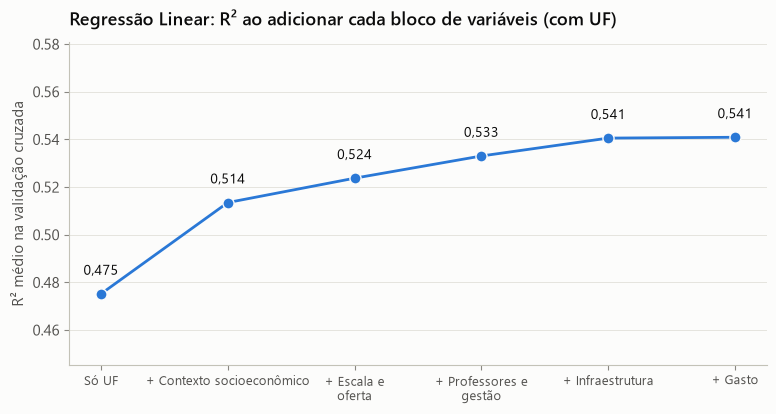

,modelo,RMSE,R²,ganho de R²
0,Só UF,"0,686","0,475",NaN
1,+ Contexto socioeconômico,"0,661","0,514","0,038"
2,+ Escala e oferta,"0,654","0,524","0,010"
3,+ Professores e gestão,"0,647","0,533","0,009"
4,+ Infraestrutura,"0,642","0,541","0,008"
5,+ Gasto,"0,642","0,541","0,000"


In [6]:
blocos, acumuladas, linhas = list(GRUPOS), [], []
r = cross_validate(pipeline_linear([], ['sigla_uf']), X, y, cv=CV, scoring=PONTUACAO, n_jobs=-1)
linhas.append({'modelo': 'Só UF', 'RMSE': -r['test_RMSE'].mean(), 'R²': r['test_R²'].mean()})
for bloco in blocos:
    acumuladas += GRUPOS[bloco]
    r = cross_validate(pipeline_linear(acumuladas, ['sigla_uf']), X, y, cv=CV, scoring=PONTUACAO, n_jobs=-1)
    linhas.append({'modelo': f'+ {bloco}', 'RMSE': -r['test_RMSE'].mean(), 'R²': r['test_R²'].mean()})
ganho = pd.DataFrame(linhas)
ganho['ganho de R²'] = ganho['R²'].diff()

fig, ax = plt.subplots(figsize=(9, 4.2))
xb = np.arange(len(ganho))
ax.plot(xb, ganho['R²'], color=eg.AZUL, marker='o', markersize=8, markeredgecolor=eg.FUNDO)
for i, v in enumerate(ganho['R²']):
    ax.text(i, v + 0.008, br(v, 3), ha='center', fontsize=10, color=eg.TINTA)
ax.set_xticks(xb, [m.replace('+ ', '+ ').replace(' e ', ' e\n') for m in ganho['modelo']], fontsize=9)
ax.set_ylabel('R² médio na validação cruzada')
ax.set_ylim(ganho['R²'].min() - 0.03, ganho['R²'].max() + 0.04)
ax.set_title('Regressão Linear: R² ao adicionar cada bloco de variáveis (com UF)')
ax.grid(axis='x', visible=False)
eg.salvar_figura(fig, '03_ganho_por_bloco_features', FIGURAS)
plt.show()
ganho

O contexto socioeconômico é o bloco que mais acrescenta depois da UF. Professores e gestão e infraestrutura somam um pouco cada. O gasto por aluno, quando entra por último (depois de contexto, professores e infraestrutura), quase não acrescenta: a informação que ele carrega já estava nas outras variáveis.

### 2.2 Multicolinearidade (VIF)

Calculado na matriz que o modelo enxerga (features winsorizadas, imputadas e padronizadas, mais as colunas das UFs), ajustada no treino completo de 2023.

In [7]:
prep = md.montar_preprocessador(NUMERICAS, ['sigla_uf']).fit(X)
matriz = pd.DataFrame(prep.transform(X), columns=prep.get_feature_names_out())
matriz.insert(0, 'const', 1.0)
vif = pd.Series([variance_inflation_factor(matriz.values, i) for i in range(1, matriz.shape[1])],
                index=matriz.columns[1:])
vif_num = vif[NUMERICAS].sort_values(ascending=False)
print(f'Maior VIF entre as features numéricas: {br(vif_num.max(), 2)} ({eg.rotulo(vif_num.idxmax())})')
print(f'Features com VIF > 5: {(vif_num > 5).sum()} | VIF > 10: {(vif_num > 10).sum()}')
vif_num.head(8).rename(index=eg.rotulo).rename('VIF').to_frame()

Maior VIF entre as features numéricas: 4,93 (INSE 2015)
Features com VIF > 5: 0 | VIF > 10: 0


,VIF
INSE 2015,"4,932"
Alunos por escola (log),"4,060"
% docentes com superior,"3,637"
% docentes com formação adequada,"3,335"
% matrículas de residentes rurais,"3,328"
% matrículas em tempo integral,"3,256"
Horas-aula por dia,"3,063"
Alunos por turma,"2,803"


Todos os VIFs ficam abaixo de 5, o limite usual de alerta. A preparação do notebook 02 (resumo dos grupos e remoção dos espelhos) resolveu a redundância, e os coeficientes da Regressão Linear podem ser interpretados.

## 3. SVR (kernel RBF)

Primeiro com os hiperparâmetros padrão, depois com busca em grade. Hiperparâmetros:
- `C`: quanto o modelo é penalizado por erros fora da margem. Maior `C` = ajuste mais justo aos dados.
- `epsilon`: largura da faixa (em pontos de IDEB) dentro da qual o erro é ignorado.
- `gamma`: alcance de cada ponto no kernel RBF. Maior `gamma` = função mais irregular.

In [8]:
def pipeline_svr(**params):
    return Pipeline([('prep', md.montar_preprocessador(NUMERICAS, ['sigla_uf'])),
                     ('modelo', SVR(kernel='rbf', **params))])


_ = avaliar('SVR padrão (C=1, epsilon=0,1, gamma=scale)', pipeline_svr())

SVR padrão (C=1, epsilon=0,1, gamma=scale) RMSE 0,660 (±0,020)  MAE 0,490  R² 0,514  [4 s]


In [9]:
GRADE = {'modelo__C': [1, 3, 10],
         'modelo__epsilon': [0.1, 0.3, 0.5],
         'modelo__gamma': ['scale', 0.003, 0.01, 0.03]}
inicio = time.time()
busca = GridSearchCV(pipeline_svr(), GRADE, cv=CV, scoring='neg_root_mean_squared_error', n_jobs=-1)
busca.fit(X, y)
print(f'{len(busca.cv_results_["params"])} combinações x 5 dobras em {time.time() - inicio:.0f} s')
print('Melhores hiperparâmetros:', busca.best_params_)
print(f'RMSE da melhor combinação na busca: {br(-busca.best_score_, 3)}')

grade = (pd.DataFrame(busca.cv_results_)
         .assign(RMSE=lambda d: -d['mean_test_score'])
         [['param_modelo__C', 'param_modelo__epsilon', 'param_modelo__gamma', 'RMSE', 'std_test_score']]
         .sort_values('RMSE').head(8))
grade.columns = ['C', 'epsilon', 'gamma', 'RMSE médio', 'desvio entre dobras']
grade

36 combinações x 5 dobras em 97 s
Melhores hiperparâmetros: {'modelo__C': 10, 'modelo__epsilon': 0.5, 'modelo__gamma': 0.01}
RMSE da melhor combinação na busca: 0,643


,C,epsilon,gamma,RMSE médio,desvio entre dobras
34,10,"0,500","0,010","0,643","0,016"
29,10,"0,300","0,003","0,644","0,019"
25,10,"0,100","0,003","0,644","0,020"
33,10,"0,500","0,003","0,644","0,017"
18,3,"0,300","0,010","0,646","0,018"
14,3,"0,100","0,010","0,646","0,020"
22,3,"0,500","0,010","0,647","0,017"
30,10,"0,300","0,010","0,647","0,016"


O RMSE da melhor combinação na busca é otimista: as mesmas dobras serviram para escolher os hiperparâmetros e para medir o erro. Para comparar com os outros modelos de forma justa, fazemos uma **validação cruzada aninhada**: em cada uma das 5 dobras externas, a busca em grade roda de novo só com os dados de treino daquela dobra, e o erro é medido na dobra externa, que a busca não viu.

In [10]:
CV_INTERNA = KFold(n_splits=5, shuffle=True, random_state=7)
busca_aninhada = GridSearchCV(pipeline_svr(), GRADE, cv=CV_INTERNA,
                              scoring='neg_root_mean_squared_error', n_jobs=-1)
_ = avaliar('SVR ajustado (validação aninhada)', busca_aninhada)

SVR ajustado (validação aninhada)          RMSE 0,645 (±0,019)  MAE 0,478  R² 0,537  [290 s]


## 4. Comparação dos modelos

In [11]:
comparacao = pd.DataFrame({nome: d.mean() for nome, d in resultados.items()}).T
comparacao['RMSE (desvio entre dobras)'] = [d['RMSE'].std() for d in resultados.values()]
ref = comparacao.loc['Baseline: média da UF', 'RMSE']
comparacao['RMSE vs baseline'] = (comparacao['RMSE'] / ref - 1) * 100
comparacao = comparacao.sort_values('RMSE')
comparacao

,RMSE,MAE,R²,RMSE (desvio entre dobras),RMSE vs baseline
Regressão Linear + UF,"0,642","0,484","0,541","0,017","-6,475"
SVR ajustado (validação aninhada),"0,645","0,478","0,537","0,019","-6,062"
"SVR padrão (C=1, epsilon=0,1, gamma=scale)","0,660","0,490","0,514","0,020","-3,786"
Baseline: média da UF,"0,686","0,523","0,475","0,015","0,000"
Regressão Linear + região,"0,733","0,543","0,402","0,014","6,810"


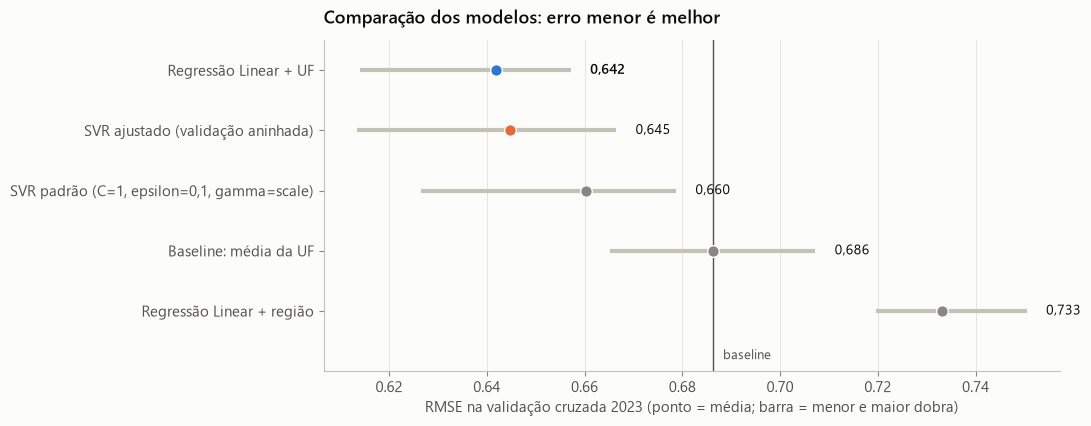

In [12]:
ordem = comparacao.index[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.3))
for i, nome in enumerate(ordem):
    dobras = resultados[nome]['RMSE']
    escolhido = nome == 'Regressão Linear + UF'
    cor = eg.AZUL if escolhido else eg.LARANJA if nome.startswith('SVR ajustado') else eg.TINTA_MUDA
    ax.hlines(i, dobras.min(), dobras.max(), color=eg.CINZA, linewidth=3)
    ax.scatter(dobras.mean(), i, s=70, color=cor, zorder=3, edgecolor=eg.FUNDO, linewidth=1)
    ax.text(dobras.max() + 0.004, i, br(dobras.mean(), 3), va='center', fontsize=10,
            color=eg.TINTA, fontweight='semibold' if escolhido else 'normal')
ax.axvline(ref, color=eg.TINTA_SEC, linewidth=1)
ax.text(ref + 0.002, -0.8, 'baseline', fontsize=9, color=eg.TINTA_SEC)
ax.set_ylim(-1, len(ordem) - 0.5)
ax.set_yticks(range(len(ordem)), ordem)
ax.set_xlabel('RMSE na validação cruzada 2023 (ponto = média; barra = menor e maior dobra)')
ax.set_title('Comparação dos modelos: erro menor é melhor')
ax.grid(axis='y', visible=False)
eg.salvar_figura(fig, '03_comparacao_modelos_cv', FIGURAS)
plt.show()

**Escolha:** a **Regressão Linear com UF** fica como modelo principal. O SVR ajustado erra praticamente o mesmo (a diferença é menor que a variação entre as dobras), então a não linearidade não trouxe ganho que compense perder a interpretação por coeficientes. Os dois seguem para o teste em 2025 no notebook 04.

## 5. Diagnóstico dos resíduos da Regressão Linear

Previsões fora da amostra (cada município é previsto pelo modelo treinado nas outras 4 dobras).

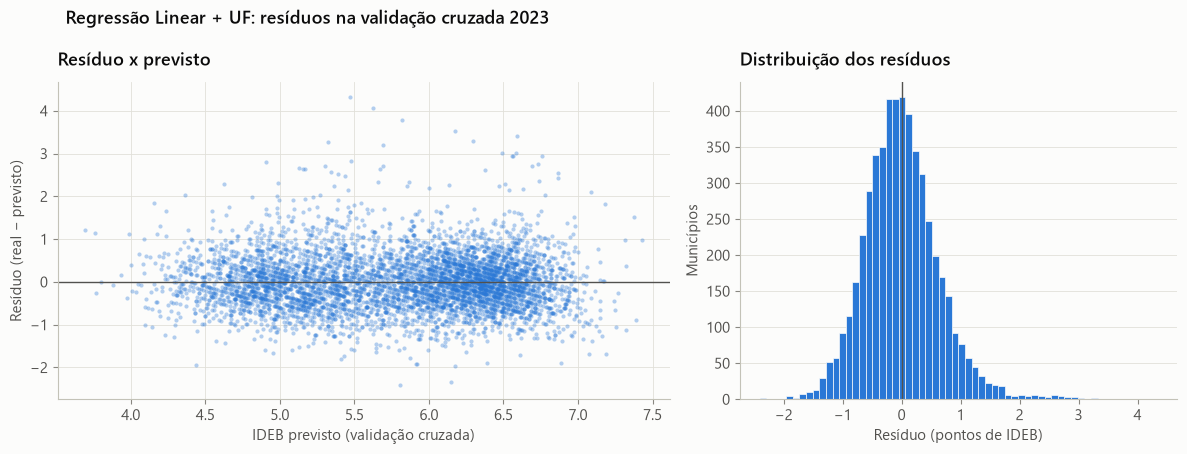

Assimetria dos resíduos: 0,78 | curtose: 2,78
2.5% dos municípios com erro acima de 1,5 ponto


In [13]:
modelo_lr = pipeline_linear(NUMERICAS, ['sigla_uf'])
previsto_cv = cross_val_predict(modelo_lr, X, y, cv=CV, n_jobs=-1)
residuo = y - previsto_cv

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.4, 1]})
ax = eixos[0]
ax.scatter(previsto_cv, residuo, s=9, color=eg.AZUL, alpha=0.35, linewidths=0)
ax.axhline(0, color=eg.TINTA_SEC, linewidth=1)
ax.set_xlabel('IDEB previsto (validação cruzada)')
ax.set_ylabel('Resíduo (real − previsto)')
ax.set_title('Resíduo x previsto')
ax = eixos[1]
ax.hist(residuo, bins=60, color=eg.AZUL, edgecolor=eg.FUNDO, linewidth=0.5)
ax.axvline(0, color=eg.TINTA_SEC, linewidth=1)
ax.set_xlabel('Resíduo (pontos de IDEB)')
ax.set_ylabel('Municípios')
ax.set_title('Distribuição dos resíduos')
ax.grid(axis='x', visible=False)
fig.suptitle('Regressão Linear + UF: resíduos na validação cruzada 2023', x=0.06, ha='left',
             fontsize=13, fontweight='semibold')
fig.tight_layout()
eg.salvar_figura(fig, '03_residuos_regressao_linear', FIGURAS)
plt.show()

print(f'Assimetria dos resíduos: {br(residuo.skew(), 2)} | curtose: {br(residuo.kurt(), 2)}')
print(f'{(residuo.abs() > 1.5).mean() * 100:.1f}% dos municípios com erro acima de 1,5 ponto')

In [14]:
por_regiao = (pd.DataFrame({'regiao': treino['regiao'], 'residuo': residuo})
              .groupby('regiao')['residuo']
              .agg(municipios='count', vies='mean', MAE=lambda r: r.abs().mean(),
                   RMSE=lambda r: np.sqrt((r ** 2).mean())))
extremos = treino['ideb'] >= 8.5
print(f'Municípios com IDEB >= 8,5: MAE {br(residuo[extremos].abs().mean(), 2)} '
      f'(contra {br(residuo[~extremos].abs().mean(), 2)} nos demais); '
      f'resíduo médio {br(residuo[extremos].mean(), 2)}')
por_regiao

Municípios com IDEB >= 8,5: MAE 2,75 (contra 0,47 nos demais); resíduo médio 2,75


,municipios,vies,MAE,RMSE
regiao,,,,
Centro-Oeste,445,"-0,000","0,462","0,582"
Nordeste,1763,"0,000","0,579","0,784"
Norte,439,"0,008","0,465","0,584"
Sudeste,1576,"-0,002","0,404","0,519"
Sul,1018,"0,000","0,460","0,588"


Os resíduos ficam centrados em zero e sem padrão claro contra o valor previsto. Com a UF no modelo, o viés por região é zero, mas o tamanho do erro não é igual: o **Nordeste** tem o maior erro (MAE de 0,58, contra 0,40 no Sudeste). A cauda direita é mais longa (assimetria positiva): o modelo subestima os municípios com IDEB muito alto, quase todos do CE e de AL, porque nenhuma variável explica por que eles ficam tão acima até dos vizinhos do mesmo estado. Esses casos não foram removidos: são justamente os que o gestor deve estudar como referência.

## 6. Análise complementar: Regressão Logística (IDEB ≥ 6)

Se a pergunta fosse "o município atinge a meta nacional de 6,0?", a tarefa seria classificação. Mesmo pipeline, mesmas dobras.

In [15]:
y_meta = (y >= 6).astype(int)
logistica = Pipeline([('prep', md.montar_preprocessador(NUMERICAS, ['sigla_uf'])),
                      ('modelo', LogisticRegression(max_iter=5000))])
METRICAS_CLASS = {'ROC AUC': 'roc_auc', 'acurácia': 'accuracy', 'acurácia balanceada': 'balanced_accuracy',
                  'F1': 'f1'}
r_log = cross_validate(logistica, X, y_meta, cv=CV, scoring=METRICAS_CLASS, n_jobs=-1)

# Baseline: proporção de municípios da UF que atingem 6,0 (calculada no treino da dobra)
prob_base = np.zeros(len(y_meta))
for idx_tr, idx_te in CV.split(X):
    prob_base[idx_te] = md.BaselineMediaUF().fit(X.iloc[idx_tr], y_meta.iloc[idx_tr]).predict(X.iloc[idx_te])
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score
classe_base = (prob_base >= 0.5).astype(int)
classificacao = pd.DataFrame({
    'Baseline: % da UF que atinge 6,0': [roc_auc_score(y_meta, prob_base), accuracy_score(y_meta, classe_base),
                                         balanced_accuracy_score(y_meta, classe_base), f1_score(y_meta, classe_base)],
    'Regressão Logística + UF': [r_log[f'test_{m}'].mean() for m in METRICAS_CLASS],
}, index=list(METRICAS_CLASS)).T
print(f'{y_meta.mean() * 100:.0f}% dos municípios atingem 6,0 em 2023')
classificacao

46% dos municípios atingem 6,0 em 2023


,ROC AUC,acurácia,acurácia balanceada,F1
"Baseline: % da UF que atinge 6,0","0,839","0,781","0,787","0,785"
Regressão Logística + UF,"0,878","0,806","0,807","0,796"


A Regressão Logística também supera o baseline e confirma os mesmos fatores, mas transforma um IDEB de 5,9 e um de 4,0 na mesma resposta ("não atingiu"). Para planejamento, a regressão do IDEB contínuo informa mais: mostra **quanto** falta. Por isso a logística fica como análise complementar.

## 7. Gravação dos resultados

In [16]:
comparacao.to_csv(PROCESSADOS / 'resultados_cv.csv')
melhores = {'svr': {k.replace('modelo__', ''): v for k, v in busca.best_params_.items()},
            'categorica_modelo': 'sigla_uf', 'modelo_principal': 'Regressão Linear + UF'}
(PROCESSADOS / 'modelos_escolhidos.json').write_text(json.dumps(melhores, ensure_ascii=False, indent=2),
                                                     encoding='utf-8')
print(json.dumps(melhores, ensure_ascii=False, indent=2))

{
  "svr": {
    "C": 10,
    "epsilon": 0.5,
    "gamma": 0.01
  },
  "categorica_modelo": "sigla_uf",
  "modelo_principal": "Regressão Linear + UF"
}


## 8. Resumo

| Modelo | RMSE (CV) | MAE | R² | Leitura |
|---|---|---|---|---|
| Baseline: média da UF | 0,686 | 0,523 | 0,475 | Só saber o estado já explica quase metade da variação |
| Regressão Linear + região | 0,733 | 0,543 | 0,402 | Pior que o baseline: a região esconde o efeito do estado |
| **Regressão Linear + UF** | **0,642** | 0,484 | **0,541** | **Modelo principal**: 6,5% menos erro que o baseline |
| SVR padrão | 0,660 | 0,490 | 0,514 | Sem ajuste, fica atrás da Regressão Linear |
| SVR ajustado (aninhada) | 0,645 | 0,478 | 0,537 | Empata com a Regressão Linear (diferença menor que a variação entre dobras) |

- O contexto socioeconômico é o bloco que mais acrescenta depois da UF (+0,038 de R²). Escala, professores e infraestrutura acrescentam cerca de 0,01 cada. O gasto por aluno, entrando por último, não acrescenta nada.
- VIF máximo de 4,93 (INSE): sem multicolinearidade preocupante.
- A melhor combinação do SVR ficou na borda da grade (C = 10, epsilon = 0,5, gamma = 0,01). As 8 melhores ficam a menos de 0,005 de RMSE entre si, abaixo da variação entre dobras, então ampliar a grade não mudaria a conclusão.
- Resíduos centrados em zero, com cauda direita: os 28 municípios com IDEB ≥ 8,5 têm erro médio de 2,75 pontos, todos subestimados. O Nordeste concentra o maior erro (MAE 0,58, contra 0,40 no Sudeste).
- A Regressão Logística (IDEB ≥ 6) chega a ROC AUC de 0,878, contra 0,839 do baseline por UF, e fica como análise complementar.